# Customer Strategy & Business Recommendations

## Objective

This notebook translates the customer segmentation results into actionable
business strategies for restaurant operators.

Using the customer segments identified in the previous analysis, the objective
is to determine:

- which customer groups represent the greatest commercial value,
- where retention and conversion opportunities exist,
- how customer segments differ across geographic markets,
- which strategies should be prioritized for each segment,
- and which KPIs should be monitored to measure business impact.

The analysis focuses on four customer segments:

1. **Established Premium**
2. **Low Engagement**
3. **High-Value Loyalists**
4. **Conversion Potential**

The goal is to move from descriptive customer segmentation toward an
actionable Customer Intelligence framework.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
DATA_PATH = Path("../data/processed/customers_segmented.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Unique customers:", df["id_persona"].nunique())

df.head().T

Dataset shape: (30000, 18)
Unique customers: 30000


,0,1,2,3,4
id_persona,2550327378,9446112038,3098363243,4013002847,7372911048
edad,31.00,40.00,62.00,41.00,49.00
genero,Masculino,Femenino,Femenino,Masculino,Femenino
ciudad_residencia,Miami,Denver,Denver,Boston,San Diego
estrato_socioeconomico,Alto,Medio,Bajo,Alto,Bajo
frecuencia_visita,6.00,2.00,2.00,5.00,0.00
promedio_gasto_comida,67.51,44.92,9.24,30.74,0.00
ocio,Sí,Sí,Sí,Sí,No
consume_licor,No,Sí,Sí,Sí,No
preferencias_alimenticias,Vegetariano,Mariscos,Vegetariano,Carnes,Carnes


## 1. Segment-Level Business KPIs

Before defining commercial strategies, we first quantify the size, value,
and engagement characteristics of each customer segment.

The following KPIs provide a business-level view of the customer portfolio:

- number and percentage of customers,
- average visit frequency,
- average food spending,
- average income,
- Premium membership penetration.

These indicators will help identify which segments should be prioritized for
retention, activation, and conversion strategies.

In [3]:
segment_kpis = (
    df.groupby("segment")
    .agg(
        customers=("id_persona", "count"),
        avg_frequency=("frecuencia_visita", "mean"),
        avg_spending=("promedio_gasto_comida", "mean"),
        avg_income=("ingresos_mensuales", "mean"),
        premium_rate=("premium_flag", "mean")
    )
)

segment_kpis["customer_share_pct"] = (
    segment_kpis["customers"] / len(df) * 100
)

segment_kpis["premium_rate_pct"] = (
    segment_kpis["premium_rate"] * 100
)

segment_kpis = segment_kpis.drop(columns="premium_rate")

segment_kpis = segment_kpis[
    [
        "customers",
        "customer_share_pct",
        "avg_frequency",
        "avg_spending",
        "avg_income",
        "premium_rate_pct"
    ]
]

segment_kpis.round(2)

,customers,customer_share_pct,avg_frequency,avg_spending,avg_income,premium_rate_pct
segment,,,,,,
Conversion Potential,7136,23.79,3.39,32.25,"2,485.84",6.19
Established Premium,7945,26.48,4.92,34.58,"6,317.99",98.07
High-Value Loyalists,4842,16.14,7.65,69.80,"13,775.00",95.06
Low Engagement,10077,33.59,2.74,13.30,"2,685.20",0.08


### Business Insight

The customer portfolio reveals three different commercial priorities.

**Low Engagement** is the largest segment, representing 33.6% of all
customers. Its low visit frequency and average spending indicate that the
main opportunity is not immediate monetization, but customer activation and
increased visit frequency.

**Conversion Potential** represents 23.8% of the customer base. Despite
average spending of $32.25, Premium penetration is only 6.2%. This creates
a clear opportunity to test targeted Premium conversion strategies.

At the other end of the portfolio, **High-Value Loyalists** represent only
16.1% of customers but show the highest visit frequency and average spending
by a substantial margin. This makes retention and loyalty protection a
strategic priority.

**Established Premium** provides a large and stable Premium customer base,
combining strong membership penetration with solid engagement and spending.

Overall, the portfolio requires different strategies rather than a single
customer campaign: activation for Low Engagement, conversion for Conversion
Potential, retention for Established Premium, and value protection for
High-Value Loyalists.

In [4]:
# Customer-level commercial value proxy
df["estimated_value_proxy"] = (
    df["frecuencia_visita"] *
    df["promedio_gasto_comida"]
)

value_by_segment = (
    df.groupby("segment")
    .agg(
        customers=("id_persona", "count"),
        customers_with_value=("estimated_value_proxy", "count"),
        estimated_value_per_customer=("estimated_value_proxy", "mean"),
        estimated_total_value=("estimated_value_proxy", "sum")
    )
)

value_by_segment["coverage_pct"] = (
    value_by_segment["customers_with_value"] /
    value_by_segment["customers"] * 100
)

value_by_segment["estimated_value_share_pct"] = (
    value_by_segment["estimated_total_value"] /
    value_by_segment["estimated_total_value"].sum() * 100
)

value_by_segment.round(2)

,customers,customers_with_value,estimated_value_per_customer,estimated_total_value,coverage_pct,estimated_value_share_pct
segment,,,,,,
Conversion Potential,7136,6704,121.25,"812,836.81",93.95,16.35
Established Premium,7945,7448,171.67,"1,278,619.93",93.74,25.72
High-Value Loyalists,4842,4654,522.42,"2,431,334.52",96.12,48.90
Low Engagement,10077,9512,47.19,"448,825.68",94.39,9.03


### Customer Base vs. Estimated Commercial Value

Customer volume alone does not accurately represent the commercial importance
of each segment.

**High-Value Loyalists represent only 16.1% of customers but account for
approximately 48.9% of the estimated commercial value.** This concentration
makes retention of this relatively small customer group especially important.

In contrast, **Low Engagement represents 33.6% of the customer base but only
9.0% of estimated value.** This suggests that large-scale investment in this
segment should focus on cost-efficient activation strategies rather than
expensive retention incentives.

Established Premium customers show a balanced contribution, representing
26.5% of customers and approximately 25.7% of estimated value.

Conversion Potential customers represent 23.8% of the customer base and
16.4% of estimated value, creating an opportunity to increase their
commercial contribution through engagement and Premium conversion.

The estimated commercial value is a relative proxy calculated at the
customer level as visit frequency × average food spending. It should not be
interpreted as actual revenue or Customer Lifetime Value (CLV).

Because some customers have missing visit-frequency or spending information,
the proxy is available for approximately 94–96% of customers across segments.

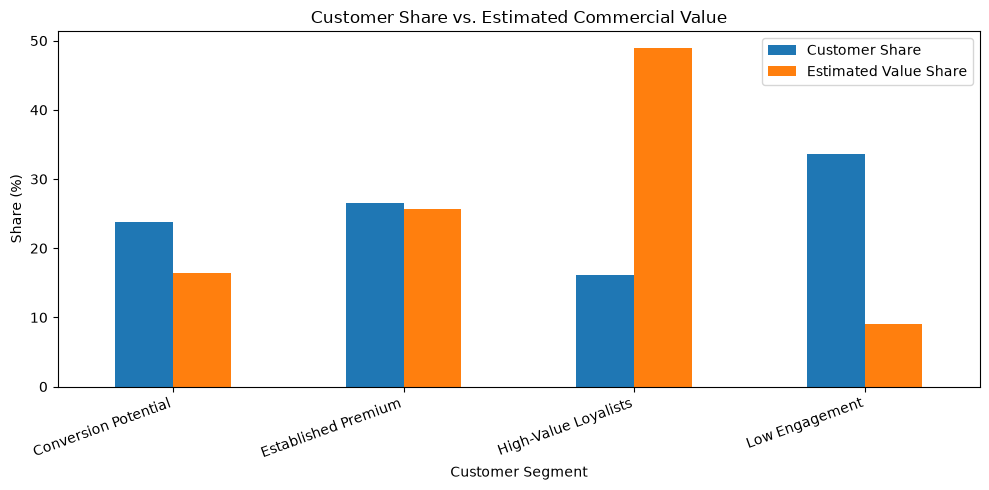

In [5]:
comparison = pd.DataFrame({
    "Customer Share": segment_kpis["customer_share_pct"],
    "Estimated Value Share": value_by_segment["estimated_value_share_pct"]
})


ax = comparison.plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Customer Share vs. Estimated Commercial Value")
ax.set_xlabel("Customer Segment")
ax.set_ylabel("Share (%)")

plt.xticks(rotation=20, ha="right")
plt.legend(title="")
plt.tight_layout()
plt.show()

## 2. Geographic Customer Strategy

Customer segments are not distributed uniformly across geographic markets.

Understanding which customer profiles are overrepresented in each city can
help restaurant operators adapt commercial strategies to local market
characteristics.

Rather than comparing raw customer counts, this analysis uses an **affinity
index**:

- **100** = expected representation
- **Above 100** = segment is overrepresented in that city
- **Below 100** = segment is underrepresented in that city

This allows cities of different sample sizes to be compared more fairly.

In [6]:
city_segment_distribution = pd.crosstab(
    df["ciudad_residencia"],
    df["segment"],
    normalize="index"
) * 100

overall_segment_distribution = (
    df["segment"].value_counts(normalize=True) * 100
)

city_segment_affinity = (
    city_segment_distribution
    .div(overall_segment_distribution, axis=1)
    * 100
)

city_segment_affinity.round(1)

segment,Conversion Potential,Established Premium,High-Value Loyalists,Low Engagement
ciudad_residencia,,,,
Boston,65.50,103.00,112.90,115.80
Chicago,42.60,103.30,90.70,142.50
Dallas,92.60,96.50,77.90,118.60
Denver,97.50,103.00,88.70,104.90
Houston,117.50,87.70,79.80,107.00
Miami,106.20,116.60,140.60,63.00
NYC,163.30,81.20,85.90,76.80
Phoenix,135.50,95.00,96.40,80.60
San Diego,90.00,112.60,121.10,87.00


In [7]:
city_strategy = pd.DataFrame({
    "top_segment": city_segment_affinity.idxmax(axis=1),
    "top_affinity_index": city_segment_affinity.max(axis=1)
})

city_strategy.sort_values(
    "top_affinity_index",
    ascending=False
).round(1)

,top_segment,top_affinity_index
ciudad_residencia,,
NYC,Conversion Potential,163.30
Chicago,Low Engagement,142.50
Miami,High-Value Loyalists,140.60
Phoenix,Conversion Potential,135.50
San Diego,High-Value Loyalists,121.10
Dallas,Low Engagement,118.60
Seattle,Conversion Potential,117.80
Houston,Conversion Potential,117.50
Boston,Low Engagement,115.80


In [8]:
strategy_map = {
    "High-Value Loyalists": "VIP Retention & Value Protection",
    "Established Premium": "Premium Retention & Loyalty",
    "Conversion Potential": "Premium Conversion & Engagement",
    "Low Engagement": "Reactivation & Frequency Growth"
}

city_strategy["recommended_strategy"] = (
    city_strategy["top_segment"].map(strategy_map)
)

city_strategy["affinity_strength"] = pd.cut(
    city_strategy["top_affinity_index"],
    bins=[0, 110, 125, 140, float("inf")],
    labels=["Balanced / Weak", "Moderate", "Strong", "Very Strong"]
)

city_strategy.sort_values(
    "top_affinity_index",
    ascending=False
)

,top_segment,top_affinity_index,recommended_strategy,affinity_strength
ciudad_residencia,,,,
NYC,Conversion Potential,163.35,Premium Conversion & Engagement,Very Strong
Chicago,Low Engagement,142.49,Reactivation & Frequency Growth,Very Strong
Miami,High-Value Loyalists,140.60,VIP Retention & Value Protection,Very Strong
Phoenix,Conversion Potential,135.50,Premium Conversion & Engagement,Strong
San Diego,High-Value Loyalists,121.09,VIP Retention & Value Protection,Moderate
Dallas,Low Engagement,118.65,Reactivation & Frequency Growth,Moderate
Seattle,Conversion Potential,117.81,Premium Conversion & Engagement,Moderate
Houston,Conversion Potential,117.45,Premium Conversion & Engagement,Moderate
Boston,Low Engagement,115.83,Reactivation & Frequency Growth,Moderate


### Geographic Strategy Insights

Customer composition varies meaningfully across geographic markets, suggesting
that commercial strategies should be adapted to local customer profiles.

**NYC** shows the strongest affinity for Conversion Potential customers
(163.3). This market represents a particularly strong opportunity for Premium
membership conversion and engagement campaigns.

**Chicago** is strongly associated with Low Engagement customers (142.5).
Commercial efforts should therefore prioritize reactivation, visit-frequency
growth, and cost-efficient incentives rather than high-cost loyalty benefits.

**Miami** shows very strong affinity with High-Value Loyalists (140.6),
supporting a strategy focused on VIP retention, exclusive experiences, and
protecting high-value customer relationships.

**Phoenix** also presents a strong Conversion Potential opportunity (135.5),
while San Diego shows moderate affinity with High-Value Loyalists.

Seattle and Houston show moderate Conversion Potential signals, while Dallas
and Boston show moderate Low Engagement concentration.

Denver remains comparatively balanced, with its strongest affinity index only
slightly above the expected level. This suggests that a broad portfolio
strategy may be more appropriate than prioritizing a single segment.

> **Interpretation note:** Affinity-strength thresholds are analytical
> guidelines created for this project to support business interpretation.
> They should not be considered universal statistical thresholds.

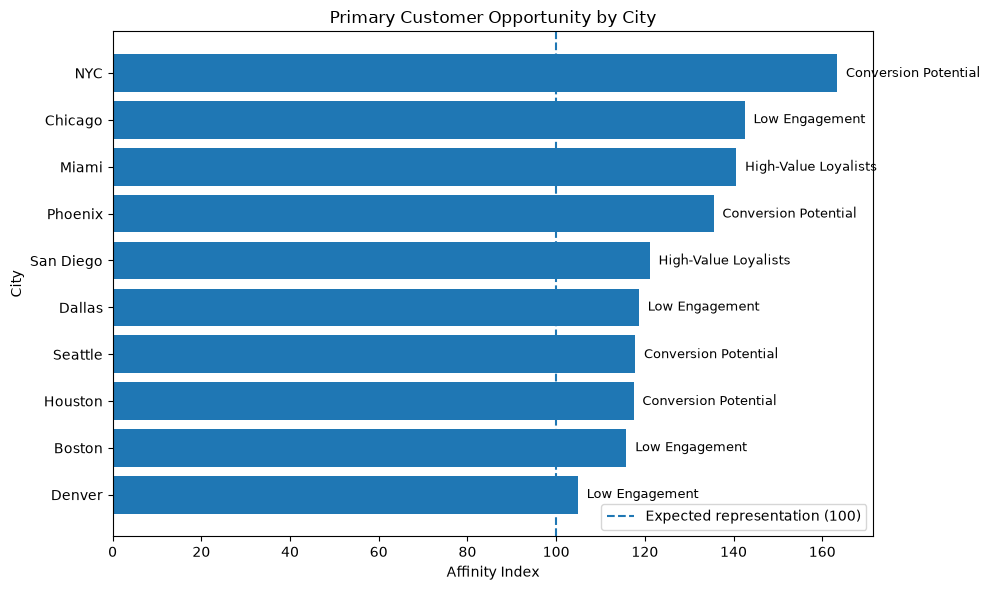

In [9]:
city_plot = (
    city_strategy
    .sort_values("top_affinity_index")
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    city_plot.index,
    city_plot["top_affinity_index"]
)

ax.axvline(
    100,
    linestyle="--",
    linewidth=1.5,
    label="Expected representation (100)"
)

for bar, segment in zip(bars, city_plot["top_segment"]):
    ax.text(
        bar.get_width() + 2,
        bar.get_y() + bar.get_height() / 2,
        segment,
        va="center",
        fontsize=9
    )

ax.set_title("Primary Customer Opportunity by City")
ax.set_xlabel("Affinity Index")
ax.set_ylabel("City")

ax.legend()
plt.tight_layout()
plt.show()

## 3. Customer Strategy Action Matrix

Customer segmentation becomes valuable when each segment is connected to a
specific business objective, an actionable commercial strategy, and measurable
KPIs.

The following framework translates the four customer segments into recommended
business actions.

The objective is not to apply the same marketing strategy to every customer,
but to allocate commercial efforts according to customer value, engagement,
and growth potential.

In [10]:
strategy_matrix = pd.DataFrame({
    "segment": [
        "High-Value Loyalists",
        "Established Premium",
        "Conversion Potential",
        "Low Engagement"
    ],

    "business_objective": [
        "Protect customer value",
        "Retain and strengthen loyalty",
        "Increase Premium conversion",
        "Increase engagement and visit frequency"
    ],

    "recommended_action": [
        "VIP experiences, exclusive events, priority reservations and personalized retention offers",
        "Loyalty rewards, exclusive benefits, personalized offers and early-access experiences",
        "Premium trials, targeted membership offers, bundled benefits and conversion campaigns",
        "Reactivation campaigns, visit incentives, entry-level promotions and personalized offers"
    ],

    "primary_kpi": [
        "Retention rate",
        "Premium retention rate",
        "Premium conversion rate",
        "Repeat visit rate"
    ],

    "secondary_kpi": [
        "Estimated value per customer",
        "Visit frequency",
        "Visit frequency",
        "Average spending"
    ]
})

strategy_matrix

,segment,business_objective,recommended_action,primary_kpi,secondary_kpi
0,High-Value Loyalists,Protect customer value,"VIP experiences, exclusive events, priority re...",Retention rate,Estimated value per customer
1,Established Premium,Retain and strengthen loyalty,"Loyalty rewards, exclusive benefits, personali...",Premium retention rate,Visit frequency
2,Conversion Potential,Increase Premium conversion,"Premium trials, targeted membership offers, bu...",Premium conversion rate,Visit frequency
3,Low Engagement,Increase engagement and visit frequency,"Reactivation campaigns, visit incentives, entr...",Repeat visit rate,Average spending


In [11]:
investment_priority = {
    "High-Value Loyalists": "Very High",
    "Established Premium": "High",
    "Conversion Potential": "Growth",
    "Low Engagement": "Cost-Efficient"
}

strategy_matrix["investment_priority"] = (
    strategy_matrix["segment"].map(investment_priority)
)

strategy_matrix

,segment,business_objective,recommended_action,primary_kpi,secondary_kpi,investment_priority
0,High-Value Loyalists,Protect customer value,"VIP experiences, exclusive events, priority re...",Retention rate,Estimated value per customer,Very High
1,Established Premium,Retain and strengthen loyalty,"Loyalty rewards, exclusive benefits, personali...",Premium retention rate,Visit frequency,High
2,Conversion Potential,Increase Premium conversion,"Premium trials, targeted membership offers, bu...",Premium conversion rate,Visit frequency,Growth
3,Low Engagement,Increase engagement and visit frequency,"Reactivation campaigns, visit incentives, entr...",Repeat visit rate,Average spending,Cost-Efficient


### Resource Allocation Insight

The analysis also suggests that marketing resources should not be distributed
equally across customer segments.

**High-Value Loyalists** should receive the highest level of retention
investment because they represent approximately 50.9% of estimated commercial
value despite accounting for only 16.1% of customers.

**Established Premium** customers also justify strong retention investment
because they combine substantial portfolio value with very high Premium
membership penetration.

**Conversion Potential** should be treated as a growth segment. Investment
should focus on measurable conversion experiments designed to increase
Premium adoption and visit frequency.

**Low Engagement** requires a different approach. Although it is the largest
segment by customer count, it represents only about 7.2% of estimated
commercial value. Strategies should therefore prioritize scalable,
cost-efficient reactivation rather than expensive individual incentives.

This framework allows commercial resources to be allocated according to
customer value and growth potential rather than customer volume alone.

## 4. Strategy Experiments & Measurement

Business recommendations should be tested before being implemented at scale.

Each customer segment can be associated with a measurable experiment designed
to evaluate whether the proposed strategy produces a meaningful improvement
in customer behavior.

A controlled experiment can compare a treatment group receiving the proposed
action with a control group continuing under the existing business strategy.

The primary KPI should be defined before launching the experiment, allowing
the business to evaluate whether the intervention produces a measurable
commercial impact.

In [12]:
experiment_matrix = pd.DataFrame({
    "segment": [
        "High-Value Loyalists",
        "Established Premium",
        "Conversion Potential",
        "Low Engagement"
    ],

    "experiment": [
        "VIP retention benefit",
        "Enhanced loyalty benefit",
        "Premium membership offer",
        "Return-visit incentive"
    ],

    "treatment": [
        "Offer exclusive VIP benefit or experience",
        "Offer additional loyalty reward or exclusive benefit",
        "Offer targeted Premium trial or membership incentive",
        "Offer time-limited incentive for the next visit"
    ],

    "control": [
        "Existing customer experience",
        "Existing Premium benefits",
        "No targeted Premium offer",
        "No return-visit incentive"
    ],

    "primary_kpi": [
        "Retention rate",
        "Premium retention rate",
        "Premium conversion rate",
        "Repeat visit rate"
    ],

    "expected_business_effect": [
        "Reduce loss of high-value customers",
        "Strengthen loyalty among Premium customers",
        "Increase Premium adoption",
        "Increase customer visit frequency"
    ]
})

experiment_matrix

,segment,experiment,treatment,control,primary_kpi,expected_business_effect
0,High-Value Loyalists,VIP retention benefit,Offer exclusive VIP benefit or experience,Existing customer experience,Retention rate,Reduce loss of high-value customers
1,Established Premium,Enhanced loyalty benefit,Offer additional loyalty reward or exclusive b...,Existing Premium benefits,Premium retention rate,Strengthen loyalty among Premium customers
2,Conversion Potential,Premium membership offer,Offer targeted Premium trial or membership inc...,No targeted Premium offer,Premium conversion rate,Increase Premium adoption
3,Low Engagement,Return-visit incentive,Offer time-limited incentive for the next visit,No return-visit incentive,Repeat visit rate,Increase customer visit frequency


### Experimental Hypotheses

Each proposed experiment should be evaluated using a predefined hypothesis
and success metric.

For each experiment:

- **Null hypothesis (H₀):** the proposed intervention does not improve the
  primary KPI compared with the control group.
- **Alternative hypothesis (H₁):** the intervention improves the primary KPI
  compared with the control group.

The effect can be measured using both absolute and relative uplift.

**Absolute uplift**

`Treatment KPI − Control KPI`

**Relative uplift**

`(Treatment KPI − Control KPI) / Control KPI × 100`

For example, if a Premium conversion campaign produces a 12% conversion rate
in the treatment group and an 8% conversion rate in the control group:

- Absolute uplift = 4 percentage points
- Relative uplift = 50%

However, uplift alone is not sufficient to determine whether an intervention
should be implemented. The result should also be evaluated considering
statistical significance, experiment sample size, campaign cost, and expected
commercial impact.

Because this dataset does not contain experimental outcomes, this notebook
defines the measurement framework but does not simulate or claim campaign
results.

In [13]:
measurement_framework = pd.DataFrame({
    "segment": [
        "High-Value Loyalists",
        "Established Premium",
        "Conversion Potential",
        "Low Engagement"
    ],
    "primary_kpi": [
        "Retention rate",
        "Premium retention rate",
        "Premium conversion rate",
        "Repeat visit rate"
    ],
    "measurement": [
        "Treatment retention vs. control retention",
        "Treatment Premium retention vs. control Premium retention",
        "Treatment conversion vs. control conversion",
        "Treatment repeat visits vs. control repeat visits"
    ],
    "decision_question": [
        "Does the VIP benefit reduce high-value customer loss?",
        "Does the enhanced benefit improve Premium retention?",
        "Does the targeted offer increase Premium adoption?",
        "Does the incentive increase repeat visits?"
    ]
})

measurement_framework

,segment,primary_kpi,measurement,decision_question
0,High-Value Loyalists,Retention rate,Treatment retention vs. control retention,Does the VIP benefit reduce high-value custome...
1,Established Premium,Premium retention rate,Treatment Premium retention vs. control Premiu...,Does the enhanced benefit improve Premium rete...
2,Conversion Potential,Premium conversion rate,Treatment conversion vs. control conversion,Does the targeted offer increase Premium adopt...
3,Low Engagement,Repeat visit rate,Treatment repeat visits vs. control repeat visits,Does the incentive increase repeat visits?


## 5. Executive Strategy Summary

The customer intelligence analysis shows that customer volume and customer
value are not distributed equally across the portfolio.

### Strategic Priority 1 — Protect High-Value Customers

High-Value Loyalists represent only 16.1% of customers but account for
approximately 48.9% of estimated commercial value.

This segment should receive the highest retention priority through VIP
experiences, personalized benefits, and loyalty initiatives designed to
protect existing customer value.

Miami shows particularly strong affinity with this customer profile.

### Strategic Priority 2 — Convert High-Potential Customers

Conversion Potential represents 23.8% of customers and combines relatively
strong spending with only 6.2% Premium membership penetration.

This creates a measurable opportunity for targeted Premium conversion
campaigns.

NYC presents the strongest geographic opportunity for this strategy, followed
by Phoenix.

### Strategic Priority 3 — Maintain the Premium Customer Base

Established Premium customers represent 26.5% of the portfolio and
approximately 25.7% of estimated commercial value.

With Premium penetration above 98%, the objective should focus primarily on
retention, loyalty, and maintaining engagement rather than acquisition.

### Strategic Priority 4 — Reactivate Efficiently

Low Engagement is the largest segment, representing 33.6% of customers, but
only approximately 9.0% of estimated commercial value.

This segment should therefore be addressed through scalable and
cost-efficient reactivation strategies focused on increasing repeat visits
and spending.

Chicago presents the strongest concentration of this customer profile.

### Recommended Decision Framework

The analysis suggests that restaurant operators should avoid applying the
same commercial strategy across the entire customer base.

Instead:

- protect value where customer value is already high,
- invest in conversion where growth potential exists,
- strengthen loyalty among established Premium customers,
- and use cost-efficient activation strategies for low-engagement customers.

Geographic affinity should also be considered when allocating campaigns,
allowing customer strategy to adapt to the characteristics of each market.

## Conclusion

This notebook translated customer segmentation into an actionable commercial
strategy.

The analysis connected customer segments with:

- commercial value,
- geographic market opportunities,
- business objectives,
- recommended actions,
- investment priorities,
- measurable KPIs,
- and controlled experiment proposals.

The results demonstrate how customer analytics can move beyond descriptive
segmentation and support evidence-based commercial decision-making.

The proposed strategies should be validated through controlled experiments
before being implemented at scale.

A future implementation using transactional restaurant data could extend this
framework with Customer Lifetime Value, churn prediction, campaign response
modeling, and real-time customer targeting.